# D2 · Horas de autonomía del tanque

**Integrante responsable: Claudio Bustinza Inofuente**

Notebook de sustentación de la dimensión D2 (Unidad 2, Grupo Horeb, MonitorAqua).

- **Modelo versionado:** `d2.2` (`batch/modelos/d2/d2.2-20261029/perfil.json`): perfil de consumo por hora del día con
  banda P10-P90 calibrada por predicción conforme. Base: `d2.1` (Holt + GBT de Spark MLlib, `batch/modelos/d2/d2.1-20261029/`).
- **Sin modelo propio:** todo se importa de `batch/modelo_d2.py`, `batch/modelo_d2_perfil.py` y `batch/evaluacion.py`;
  el notebook solo carga, verifica, evalúa y grafica.
- **Fuente de verdad:** `docs/modelo-d2.md` y `docs/evidencias/f6-d2/d2.2/`.

In [1]:
# Dependencias que la imagen de Jupyter no trae (lectura de Parquet y gráficos). Versiones fijas.
%pip install -q --root-user-action=ignore --disable-pip-version-check pyarrow==19.0.1 matplotlib==3.10.7

Note: you may need to restart the kernel to use updated packages.


In [2]:
import json, sys, time, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))          # notebooks/u2/soporte_u2.py
import soporte_u2 as su                        # agrega batch/, ingesta/ y streaming/ al path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
import evaluacion as ev
import modelo_d2 as m
import modelo_d2_perfil as p
RAIZ = su.RAIZ
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
warnings.filterwarnings("ignore", category=FutureWarning)
MODELO = RAIZ / "batch/modelos/d2/d2.2-20261029"
PUB = json.loads((RAIZ / "docs/evidencias/f6-d2/d2.2/resultados_d2.2.json").read_text(encoding="utf-8"))
D21 = json.loads((RAIZ / "docs/evidencias/f6-d2/resultados_d2.json").read_text(encoding="utf-8"))
print("Repositorio:", RAIZ)

Repositorio: /work/MonitorAqua


## 1. Pregunta y datos

**Pregunta:** ¿cuántas horas le quedan al tanque antes de quedar casi vacío (umbral 10 %, configurable) si se sigue
gastando como en las últimas horas? **Decisión que apoya:** racionar, pedir cisterna o llenar mientras hay servicio.

**Datos:** tabla oro `d2_autonomia` (nivel % cada 5 min, mediana por bloque, tramos sin rellenar). La partición es
temporal y única para las cuatro dimensiones; aquí se lee la vigente, **p6.2**. p6.2 solo mueve el inicio de la
prueba del ESP32 (que sigue sin datos de prueba mientras la geometría sea provisional): flota y ThingSpeak son los
mismos que con p6.1, con la que se publicó d2.2. Se comprueba más abajo, número por número.

In [3]:
d2 = ev.leer_oro("d2_autonomia").dropna(subset=["nivel_pct"])
d2["runId"] = d2["runId"].fillna("")
print("Partición de la tabla oro:", ", ".join(d2["particion_version"].unique()))
conteo = pd.crosstab(d2["fuente"].map(ev.nivel_de), d2["particion"], margins=True, margins_name="total")
conteo.index.name = "nivel"
display(conteo)
print("Sensores por nivel:", d2.assign(nivel=d2["fuente"].map(ev.nivel_de)).groupby("nivel")["sensorId"].nunique().to_dict())

Partición de la tabla oro: p6.2


particion,consistencia,embargo,entrenamiento,prueba,total
nivel,,,,,
consistencia,18343,2284,48172,0,68799
esp32_real,0,0,252,0,252
thingspeak_real,0,555,36199,5550,42304
total,18343,2839,84623,5550,111355


Sensores por nivel: {'consistencia': 4, 'esp32_real': 1, 'thingspeak_real': 5}


## 2. Líneas base

| Qué se predice | Líneas base |
|---|---|
| Nivel a 15 y 60 min | **persistencia** ŷ(t+h) = y(t) y **tendencia lineal** de la última hora (`ev.lineas_base`) |
| Consumo en 6, 12 y 24 h (evidencia principal) | **consumo medio** del tanque y **Holt d2.1** (sin reajustar) |
| Autonomía hasta el 10 % | **consumo medio**, **Holt d2.1**, persistencia y tendencia de la velocidad (d2.1), GBT d2.1 |

Las líneas base del nivel, solas, sobre los conjuntos finales (antes de exigir que el modelo tenga predicción):

In [4]:
FINAL = dict(p.FINAL)
base = ev.lineas_base(d2, "nivel_pct", m.PASO_MS, 12, p.CFG["tendencia_k"], grupo=m.SERIE)
base["nivel"] = base["fuente"].map(ev.nivel_de)
solo_bases = ev.reporte({n: base[(base["nivel"] == n) & (base["particion"] == FINAL[n])] for n in FINAL}, (),
                        largo_bloque=p.CFG["bootstrap"]["largo_bloque"], n_boot=p.CFG["bootstrap"]["n_boot"])
filas = []
for nivel, r in solo_bases.items():
    for pred, mt in (r.get("predictores") or {}).items():
        d = base[(base["nivel"] == nivel) & (base["particion"] == FINAL[nivel])]
        filas.append({"nivel": nivel, "línea base (nivel a 60 min)": pred.removeprefix("pred_"), "n": mt["n"],
                      "MAE [IC 95 %]": su.fm(mt["MAE"]), "RMSE [IC 95 %]": su.fm(mt["RMSE"]),
                      "R²": round(su.r2(d["y_real"], d[pred]), 3)})
display(pd.DataFrame(filas) if filas else "sin datos")

,nivel,línea base (nivel a 60 min),n,MAE [IC 95 %],RMSE [IC 95 %],R²
0,consistencia,persistencia,17902,"2.66 [2.43, 2.94]","6.53 [5.78, 7.38]",0.868
1,consistencia,tendencia,17902,"3.22 [2.84, 3.63]","9.68 [8.59, 10.63]",0.709
2,thingspeak_real,persistencia,4315,"1.13 [0.93, 1.35]","3.08 [2.59, 3.54]",0.983
3,thingspeak_real,tendencia,4315,"1.99 [1.64, 2.38]","4.92 [4.13, 5.68]",0.956


## 3. Modelo: carga del versionado y reentrenamiento verificado

Se cargan los parámetros guardados de d2.2 y se **reentrena** con las mismas funciones (`p.aprender_perfiles`,
`p.calibrar_banda`) sobre el entrenamiento de la partición. Los perfiles deben salir idénticos a los guardados.

In [5]:
guardado = json.loads((MODELO / "perfil.json").read_text(encoding="utf-8"))
print("Modelo:", guardado["version"], guardado["fecha"], "·", guardado["modelo"])
df = m.preparar(d2, p.UMBRALES).sort_values(m.SERIE + ["ts"]).reset_index(drop=True)
df["fila"] = np.arange(len(df))
t0 = time.time()
perfiles = p.aprender_perfiles(df)
print(f"Reentrenado en {time.time() - t0:.1f} s: {len(perfiles)} perfiles (tanques)")
filas = []
for clave, perfil in perfiles.items():
    k = "|".join(clave)
    viejo = {kk: vv for kk, vv in guardado["tanques"][k].items() if kk != "consumo_medio_pct_h"}
    igual = json.dumps(perfil.a_dict(), sort_keys=True) == json.dumps(viejo, sort_keys=True)
    filas.append({"tanque": k, "idéntico al guardado": "sí" if igual else "NO",
                  "consumo medio %/h": round(perfil.consumo_medio_h(), 4)})
tabla_perfiles = pd.DataFrame(filas)
display(tabla_perfiles)
cal = p.calibrar_banda(df)
print("Calibración de la banda idéntica a la guardada:",
      json.dumps(su.normalizar(cal), sort_keys=True) == json.dumps(guardado["calibracion_banda"], sort_keys=True))
print("Factor conforme:", {n: round(c["factor"], 3) for n, c in cal.items()})

Modelo: d2.2 20261029 · perfil de consumo por hora (batch/perfil_consumo.py)


{"service": "f6-d2.2", "status": "perfiles", "tanques": 13, "bloques": 7536, "solo_conj": null}


Reentrenado en 0.4 s: 13 perfiles (tanques)


,tanque,idéntico al guardado,consumo medio %/h
0,aumentado_f2b1|flota-zonaA-01|r2026-45facae2,sí,1.4790
1,aumentado_f2b1|flota-zonaA-02|r2026-45facae2,sí,1.9641
2,aumentado_f2b1|flota-zonaB-01|r2026-45facae2,sí,1.4016
3,aumentado_f2b1|flota-zonaB-02|r2026-45facae2,sí,0.9427
4,aumentado_f2b2|flota-zonaA-01|r7-79a6b935,sí,1.4966
5,aumentado_f2b2|flota-zonaA-02|r7-79a6b935,sí,2.1311
6,aumentado_f2b2|flota-zonaB-01|r7-79a6b935,sí,1.5295
7,aumentado_f2b2|flota-zonaB-02|r7-79a6b935,sí,0.9160
8,esp32|esp32-tanque-real-01|,NO,1.8430
9,thingspeak|thingspeak-1233810|,sí,0.6756


{"service": "f6-d2.2", "status": "perfiles", "tanques": 13, "bloques": 6027, "solo_conj": "entrenamiento"}


{"service": "f6-d2.2", "status": "banda_calibrada", "consistencia": 1.0266666666666666, "thingspeak_real": 1.7999999999999998, "esp32_real": 1.7999999999999998}


Calibración de la banda idéntica a la guardada: True
Factor conforme: {'consistencia': 1.027, 'thingspeak_real': 1.8, 'esp32_real': 1.8}


El único perfil que puede cambiar es el del ESP32: no entra en ninguna métrica (no tiene periodo de prueba) y su
perfil es provisional por diseño (`nota_esp32` del modelo). Si aparece "NO", es por esa razón: sus filas de
entrenamiento cambiaron al aplicar el rango válido de cada sensor (HC-SR04 / JSN-SR04T) y p6.2. Los perfiles de la
flota y de ThingSpeak, que son los evaluados, deben ser idénticos.

In [6]:
evaluados = tabla_perfiles[~tabla_perfiles["tanque"].str.startswith("esp32")]
assert (evaluados["idéntico al guardado"] == "sí").all(), "un perfil evaluado no coincide con el guardado"
print(f"Verificado: los {len(evaluados)} perfiles evaluados (flota y ThingSpeak) son idénticos a los guardados.")

Verificado: los 12 perfiles evaluados (flota y ThingSpeak) son idénticos a los guardados.


### 3.1 Spark MLlib: entrenamiento distribuido del GBT (comparación de d2.1)

`m.entrenar_gbt` entrena con `GBTRegressor` de Spark MLlib (sesión `local[4]`): grilla de `maxDepth` × `maxIter`
elegida en el conjunto de ajuste y modelo final con entrenamiento + ajuste, para 15 y 60 min, en la flota y en
ThingSpeak. Se entrena en una carpeta temporal (no toca los modelos versionados) y se compara con lo guardado.

In [7]:
import tempfile
tmp = Path(tempfile.mkdtemp(prefix="gbt_d2_"))
t0 = time.time()
gbt_nuevo, resumen_gbt = m.entrenar_gbt(df, tmp)
print(f"GBT entrenados con Spark MLlib en {time.time() - t0:.0f} s")
man = json.loads((RAIZ / "docs/evidencias/f6-d2/manifiesto_modelos.json").read_text(encoding="utf-8"))["gbt"]
display(pd.DataFrame([{"modelo": k, "hiperparámetros elegidos": f"maxDepth {v['elegido']['maxDepth']}, maxIter {v['elegido']['maxIter']}",
                       "guardado": f"maxDepth {man[k]['maxDepth']}, maxIter {man[k]['maxIter']}",
                       "MAE ajuste": round(v['elegido']['mae_ajuste'], 4), "MAE ajuste guardado": round(man[k]['mae_ajuste'], 4),
                       "filas entrenamiento": v["filas_entrenamiento_final"],
                       "variable más importante": next(iter(v["importancias_top8"]))} for k, v in resumen_gbt.items()]))

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/30 14:13:31 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


26/10/30 14:13:47 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


26/10/30 14:13:48 WARN TaskSetManager: Stage 0 contains a task of very large size (12375 KiB). The maximum recommended task size is 1000 KiB.


26/10/30 14:13:49 WARN TaskSetManager: Stage 1 contains a task of very large size (12375 KiB). The maximum recommended task size is 1000 KiB.


26/10/30 14:13:51 WARN TaskSetManager: Stage 2 contains a task of very large size (12375 KiB). The maximum recommended task size is 1000 KiB.


... (2,161 outputs left out)

26/10/30 14:23:51 WARN TaskSetManager: Stage 8650 contains a task of very large size (12375 KiB). The maximum recommended task size is 1000 KiB.


26/10/30 14:23:51 WARN TaskSetManager: Stage 8653 contains a task of very large size (12375 KiB). The maximum recommended task size is 1000 KiB.


GBT entrenados con Spark MLlib en 626 s


,modelo,hiperparámetros elegidos,guardado,MAE ajuste,MAE ajuste guardado,filas entrenamiento,variable más importante
0,gbt_h15_consistencia,"maxDepth 5, maxIter 60","maxDepth 5, maxIter 60",0.4212,0.4212,47566,d1
1,gbt_h60_consistencia,"maxDepth 3, maxIter 60","maxDepth 3, maxIter 60",1.9341,1.9341,47260,hora_sin
2,gbt_h15_thingspeak,"maxDepth 3, maxIter 30","maxDepth 3, maxIter 30",0.3375,0.3375,21681,y0
3,gbt_h60_thingspeak,"maxDepth 2, maxIter 30","maxDepth 2, maxIter 30",0.8044,0.8044,32439,l2


## 4. Resultados por nivel

Se evalúa con las funciones de `batch/modelo_d2_perfil.py` y los modelos guardados (perfil d2.2, Holt d2.1 y los
GBT d2.1 guardados, **sin reentrenar**). Después se comparan **todos** los números con
`docs/evidencias/f6-d2/d2.2/resultados_d2.2.json` y se regenera la tabla publicada (`tablas_d2.2.md`, la misma de
`docs/modelo-d2.md`) para comprobar que sale idéntica.

In [8]:
holt21 = json.loads((RAIZ / p.CFG2["base_d21"] / "holt.json").read_text(encoding="utf-8"))["parametros"]
t0 = time.time()
df = p.predecir(df, perfiles, holt21, RAIZ / p.CFG2["base_d21"])
res = {"autonomia": {str(u): p.evaluar_autonomia(df, u, cal) for u in p.UMBRALES}}
res["consumo"], ventanas = p.evaluar_consumo(df, perfiles, con_tabla=True)
res["nivel"], pares = {}, {}
for minutos in p.CFG["horizontes_min"]:
    res["nivel"][str(minutos)], pares[minutos] = p.evaluar_nivel(df, d2, minutos, con_tabla=True)
print(f"Evaluación completa en {time.time() - t0:.0f} s")
for parte in ("consumo", "autonomia", "nivel"):
    su.informe_comparacion(parte, res[parte], PUB[parte])
publicado = {**PUB, "calibracion_banda": cal, **res}
su.misma_tabla(p.tablas_md(su.normalizar(publicado), D21), RAIZ / "docs/evidencias/f6-d2/d2.2/tablas_d2.2.md")

26/10/30 14:24:04 WARN TaskSetManager: Stage 5 contains a task of very large size (11350 KiB). The maximum recommended task size is 1000 KiB.


26/10/30 14:24:06 WARN TaskSetManager: Stage 11 contains a task of very large size (11350 KiB). The maximum recommended task size is 1000 KiB.


26/10/30 14:24:08 WARN TaskSetManager: Stage 17 contains a task of very large size (11350 KiB). The maximum recommended task size is 1000 KiB.


26/10/30 14:24:09 WARN TaskSetManager: Stage 23 contains a task of very large size (11350 KiB). The maximum recommended task size is 1000 KiB.


26/10/30 14:24:11 WARN TaskSetManager: Stage 29 contains a task of very large size (11350 KiB). The maximum recommended task size is 1000 KiB.


26/10/30 14:24:12 WARN TaskSetManager: Stage 35 contains a task of very large size (11350 KiB). The maximum recommended task size is 1000 KiB.


Evaluación completa en 212 s
consumo: 684 de 684 números idénticos a lo publicado
autonomia: 1172 de 1172 números idénticos a lo publicado
nivel: 370 de 370 números idénticos a lo publicado
tablas_d2.2.md: idéntica a la regenerada con los datos de hoy


True

In [9]:
NOMBRE = {"perfil_p50": "perfil P50 (d2.2)", "consumo_medio": "consumo medio (base)", "holt_d21": "Holt d2.1 (base)"}
filas = []
for nivel in ("consistencia", "thingspeak_real", "esp32_real"):
    for h in ("6", "12", "24"):
        b = res["consumo"].get(nivel, {})
        if "predictores" not in b.get(h, {}):
            if h == "6":
                filas.append({"nivel": nivel, "qué": "consumo previsto (% cap.)", "H": "6, 12 y 24 h", "predictor": "—",
                              "n": 0, "MAE": "pendiente (sin periodo de prueba)"})
            continue
        v = ventanas[(ventanas["nivel"] == nivel) & (ventanas["horas"] == int(h))]
        for pred, nom in NOMBRE.items():
            mt = b[h]["predictores"][pred]["pct"]
            filas.append({"nivel": nivel, "qué": "consumo previsto (% cap.)", "H": f"{h} h", "predictor": nom,
                          "n": mt["n"], "MAE": su.fm(mt["MAE"], 1), "RMSE": su.fm(mt["RMSE"], 1),
                          "R²": round(su.r2(v["real"], v[pred]), 3),
                          "MAE publicado": round(PUB["consumo"][nivel][h]["predictores"][pred]["pct"]["MAE"]["valor"], 1)})
resultados_consumo = pd.DataFrame(filas)
display(Markdown("**Consumo previsto frente al real (evidencia principal de d2.2)**"))
display(resultados_consumo)

**Consumo previsto frente al real (evidencia principal de d2.2)**

,nivel,qué,H,predictor,n,MAE,RMSE,R²,MAE publicado
0,consistencia,consumo previsto (% cap.),6 h,perfil P50 (d2.2),1367,"3.8 [3.4, 4.1]","5.3 [4.8, 5.6]",0.561,3.8
1,consistencia,consumo previsto (% cap.),6 h,consumo medio (base),1367,"5.7 [5.2, 6.1]","7.4 [6.9, 7.8]",0.144,5.7
2,consistencia,consumo previsto (% cap.),6 h,Holt d2.1 (base),1367,"8.0 [7.7, 8.5]","9.4 [8.9, 9.8]",-0.389,8.0
3,consistencia,consumo previsto (% cap.),12 h,perfil P50 (d2.2),1245,"5.9 [5.4, 6.3]","7.2 [6.6, 7.6]",0.605,5.9
4,consistencia,consumo previsto (% cap.),12 h,consumo medio (base),1245,"8.5 [7.9, 9.1]","10.3 [9.7, 11.0]",0.187,8.5
5,consistencia,consumo previsto (% cap.),12 h,Holt d2.1 (base),1245,"14.3 [13.7, 15.1]","18.0 [17.2, 18.9]",-1.462,14.3
6,consistencia,consumo previsto (% cap.),24 h,perfil P50 (d2.2),1028,"8.0 [7.0, 8.6]","9.3 [8.1, 9.8]",0.482,8.0
7,consistencia,consumo previsto (% cap.),24 h,consumo medio (base),1028,"9.9 [9.1, 11.0]","11.2 [10.3, 11.9]",0.253,9.9
8,consistencia,consumo previsto (% cap.),24 h,Holt d2.1 (base),1028,"18.6 [17.7, 19.8]","23.7 [22.3, 25.3]",-2.364,18.6
9,thingspeak_real,consumo previsto (% cap.),6 h,perfil P50 (d2.2),278,"3.8 [2.3, 5.7]","7.9 [4.6, 11.0]",-0.093,3.8


In [10]:
filas = []
for nivel in ("consistencia", "thingspeak_real", "esp32_real"):
    r = res["nivel"]["60"][nivel]
    if not r.get("predictores"):
        filas.append({"nivel": nivel, "predictor (nivel a 60 min)": "—", "n": 0, "MAE (pp)": "pendiente (sin periodo de prueba)"})
        continue
    d = pares[60][nivel]
    for pred, mt in r["predictores"].items():
        filas.append({"nivel": nivel, "predictor (nivel a 60 min)": pred.removeprefix("pred_"), "n": mt["n"],
                      "MAE (pp)": su.fm(mt["MAE"]), "RMSE (pp)": su.fm(mt["RMSE"]), "R²": round(su.r2(d["y_real"], d[pred]), 3),
                      "MAE publicado": round(PUB["nivel"]["60"][nivel]["predictores"][pred]["MAE"]["valor"], 2)})
display(Markdown("**Pronóstico del nivel a 60 min**"))
display(pd.DataFrame(filas))
filas = []
for nivel in ("consistencia", "thingspeak_real", "esp32_real"):
    a = res["autonomia"]["10"][nivel]
    if "predictores" not in a:
        filas.append({"nivel": nivel, "predictor (autonomía hasta 10 %)": "—", "MAE (h)": "pendiente (sin periodo de prueba)"})
        continue
    for pred in ("perfil_p50", "consumo_medio", "holt_d21", "gbt_d21"):
        r = a["predictores"][pred]
        filas.append({"nivel": nivel, "predictor (autonomía hasta 10 %)": pred,
                      "MAE (h)": round(r["error_h"]["MAE"]["valor"], 1) if "error_h" in r else "—",
                      "C-index por tanque [IC 95 %]": su.fm(r["cindex_por_tanque"].get("C"), 3),
                      "C-index publicado": round(PUB["autonomia"]["10"][nivel]["predictores"][pred]["cindex_por_tanque"]["C"]["valor"], 3),
                      "episodios no censurados": a["episodios_no_censurados_evaluados"]})
display(Markdown("**Autonomía hasta el 10 %** (MAE indicativo: pocos episodios no censurados)"))
display(pd.DataFrame(filas))

**Pronóstico del nivel a 60 min**

,nivel,predictor (nivel a 60 min),n,MAE (pp),RMSE (pp),R²,MAE publicado
0,consistencia,persistencia,17887,"2.66 [2.43, 2.94]","6.53 [5.73, 7.42]",0.868,2.66
1,consistencia,tendencia,17887,"3.22 [2.83, 3.63]","9.68 [8.69, 10.71]",0.709,3.22
2,consistencia,perfil,17887,"1.99 [1.75, 2.27]","6.51 [5.68, 7.44]",0.869,1.99
3,consistencia,holt_d21,17887,"3.10 [2.84, 3.40]","6.93 [6.18, 7.77]",0.851,3.10
4,consistencia,gbt_d21,17887,"1.84 [1.67, 2.06]","4.97 [4.43, 5.54]",0.923,1.84
5,thingspeak_real,persistencia,3392,"1.30 [1.08, 1.56]","3.29 [2.82, 3.78]",0.983,1.30
6,thingspeak_real,tendencia,3392,"2.19 [1.78, 2.65]","5.04 [4.22, 5.89]",0.961,2.19
7,thingspeak_real,perfil,3392,"1.35 [1.12, 1.60]","3.31 [2.85, 3.80]",0.983,1.35
8,thingspeak_real,holt_d21,3392,"1.77 [1.48, 2.09]","3.59 [3.01, 4.15]",0.980,1.77
9,thingspeak_real,gbt_d21,3392,"1.43 [1.21, 1.68]","3.21 [2.73, 3.70]",0.984,1.43


**Autonomía hasta el 10 %** (MAE indicativo: pocos episodios no censurados)

,nivel,predictor (autonomía hasta 10 %),MAE (h),C-index por tanque [IC 95 %],C-index publicado,episodios no censurados
0,consistencia,perfil_p50,7.3,"0.958 [0.928, 0.992]",0.958,3.0
1,consistencia,consumo_medio,5.5,"0.984 [0.955, 1.000]",0.984,3.0
2,consistencia,holt_d21,12.4,"0.923 [0.879, 0.970]",0.923,3.0
3,consistencia,gbt_d21,23.6,"0.708 [0.638, 0.872]",0.708,3.0
4,thingspeak_real,perfil_p50,4.5,"0.955 [0.807, 1.000]",0.955,2.0
5,thingspeak_real,consumo_medio,2.4,"0.935 [0.719, 1.000]",0.935,2.0
6,thingspeak_real,holt_d21,35.6,"0.677 [0.533, 0.863]",0.677,2.0
7,thingspeak_real,gbt_d21,46.6,"0.605 [0.325, 0.795]",0.605,2.0
8,esp32_real,—,pendiente (sin periodo de prueba),NaN,NaN,NaN


**Lectura (igual que `docs/modelo-d2.md`):** en el consumo previsto, el perfil es el mejor en la flota en los tres
horizontes y en ThingSpeak a 6 y 12 h (IC solapados), y empata a 24 h; Holt d2.1 es el peor siempre. En el nivel a
60 min en datos reales nada supera a la persistencia (el nivel cambia a escalones). En la autonomía, el perfil no
supera a su base de consumo medio en MAE (pocos episodios), pero baja el error de d2.1 de 30-35 h a 2-7 h.

## 5. Gráficos

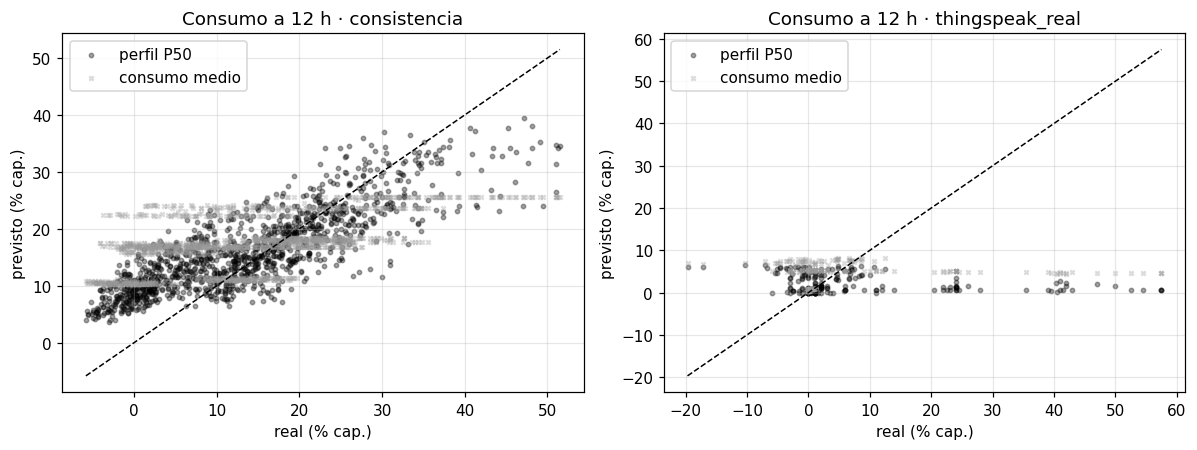

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, nivel in zip(axs, ("consistencia", "thingspeak_real")):
    v = ventanas[(ventanas["nivel"] == nivel) & (ventanas["horas"] == 12)]
    ax.scatter(v["real"], v["perfil_p50"], s=8, c="k", alpha=0.35, label="perfil P50")
    ax.scatter(v["real"], v["consumo_medio"], s=8, c="0.6", alpha=0.35, marker="x", label="consumo medio")
    lim = [min(v["real"].min(), 0), max(v["real"].max(), v["perfil_p50"].max())]
    ax.plot(lim, lim, "k--", lw=1)
    ax.set(title=f"Consumo a 12 h · {nivel}", xlabel="real (% cap.)", ylabel="previsto (% cap.)"); ax.legend()
plt.tight_layout(); plt.show()

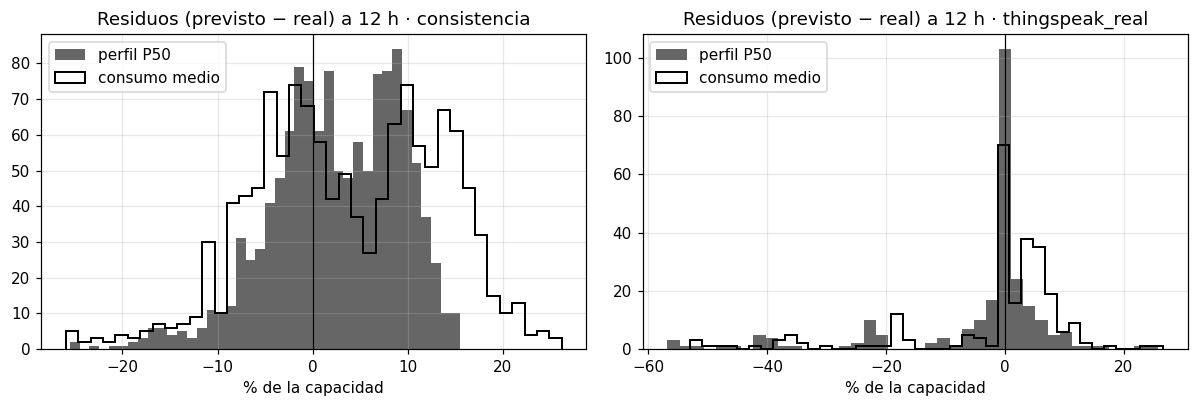

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, nivel in zip(axs, ("consistencia", "thingspeak_real")):
    v = ventanas[(ventanas["nivel"] == nivel) & (ventanas["horas"] == 12)]
    ax.hist(v["perfil_p50"] - v["real"], bins=40, color="0.25", alpha=0.8, label="perfil P50")
    ax.hist(v["consumo_medio"] - v["real"], bins=40, histtype="step", color="k", lw=1.3, label="consumo medio")
    ax.axvline(0, color="k", lw=0.8)
    ax.set(title=f"Residuos (previsto − real) a 12 h · {nivel}", xlabel="% de la capacidad"); ax.legend()
plt.tight_layout(); plt.show()

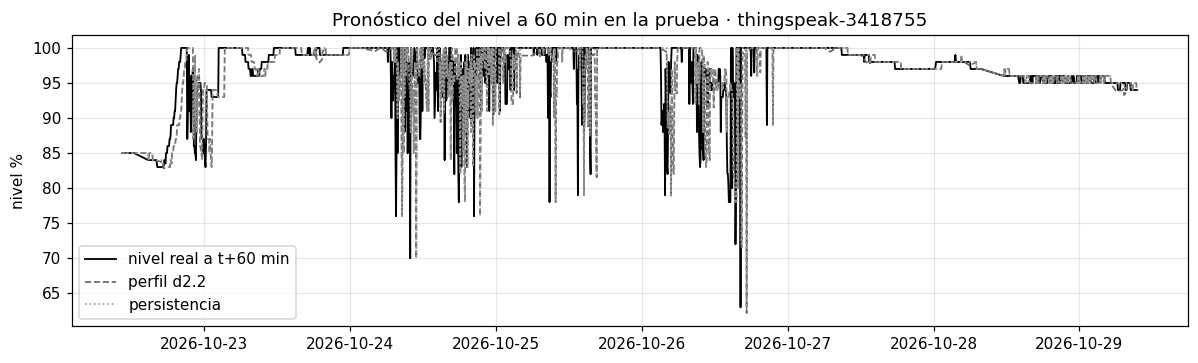

In [13]:
d = pares[60]["thingspeak_real"]
s = d["sensorId"].value_counts().index[0]
g = d[d["sensorId"] == s].sort_values("ts")
t = pd.to_datetime(g["ts"], unit="ms", utc=True).dt.tz_convert("America/Lima")
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(t, g["y_real"], "k-", lw=1.2, label="nivel real a t+60 min")
ax.plot(t, g["pred_perfil"], "--", color="0.4", lw=1.1, label="perfil d2.2")
ax.plot(t, g["pred_persistencia"], ":", color="0.6", lw=1.1, label="persistencia")
ax.set(title=f"Pronóstico del nivel a 60 min en la prueba · {s}", ylabel="nivel %"); ax.legend()
plt.tight_layout(); plt.show()

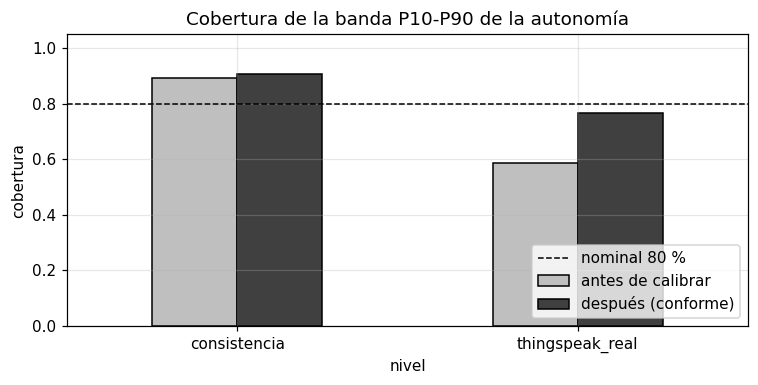

,antes de calibrar,después (conforme)
nivel,,
consistencia,0.893,0.906
thingspeak_real,0.587,0.768


In [14]:
filas = []
for nivel in ("consistencia", "thingspeak_real"):
    b = res["autonomia"]["10"][nivel].get("banda_p10_p90")
    if b:
        filas.append({"nivel": nivel, "antes de calibrar": b["antes"]["cobertura"], "después (conforme)": b["despues"]["cobertura"]})
cob = pd.DataFrame(filas).set_index("nivel")
ax = cob.plot.bar(color=["0.75", "0.25"], edgecolor="k", figsize=(7, 3.6), rot=0)
ax.axhline(0.8, color="k", ls="--", lw=1, label="nominal 80 %"); ax.set_ylim(0, 1.05)
ax.set(title="Cobertura de la banda P10-P90 de la autonomía", ylabel="cobertura"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()
display(cob.round(3))

## 6. En vivo (F7): últimas predicciones y pronóstico frente a real

La consulta `predicciones` del job de Spark (F7) aplica este mismo modelo versionado a cada micro-lote y escribe en
InfluxDB (measurement `predicciones`, `dimension = D2`). Se leen las últimas estimaciones y las verificaciones
(`tipo = verificacion`: el pronóstico comparado con lo que pasó de verdad en el instante objetivo). Los datos reales
están en el bucket `monitoraqua`; la flota extrapolada, en `monitoraqua_aumentados` (fechas simuladas 28-sep a 28-oct).

In [15]:
est = su.predicciones("D2", "estimacion", horas=48, limite=400)
if len(est):
    ult = est.sort_values("_time").groupby("sensorId").tail(1)
    cols = [c for c in ["_time", "sensorId", "version_modelo", *['autonomia_texto', 'autonomia_h', 'autonomia_p10_h', 'autonomia_p90_h', 'nivel_pct'], "advertencia"] if c in ult]
    display(ult[cols].reset_index(drop=True))
else:
    print("Sin estimaciones reales en las últimas 48 h")
mot = su.predicciones("D2", "motivo", horas=48, limite=400)
if len(mot):
    mot = mot.sort_values("_time").groupby("sensorId").tail(1)
    if len(est):   # vigente: solo si el tanque no tuvo una estimación posterior al motivo
        ult_est = est.groupby("sensorId")["_time"].max()
        mot = mot[mot["_time"] > mot["sensorId"].map(ult_est).fillna(pd.Timestamp(0, tz="America/Lima"))]
    print("Tanques reales donde hoy el modelo no aplica (motivo vigente):")
    display(mot[["_time", "sensorId", "motivo"]].reset_index(drop=True))

,_time,sensorId,version_modelo,autonomia_texto,autonomia_h,autonomia_p10_h,autonomia_p90_h,nivel_pct,advertencia
0,2026-10-30 09:10:58-05:00,thingspeak-283977,d2.2-20261029,más de 12 h,12,12.0,12,94.60,en ThingSpeak el perfil tiende a ser optimista...
1,2026-10-30 09:15:43-05:00,thingspeak-1233810,d2.2-20261029,más de 12 h,12,12.0,12,41.80,en ThingSpeak el perfil tiende a ser optimista...
2,2026-10-30 09:19:19-05:00,thingspeak-3418755,d2.2-20261029,más de 12 h,12,12.0,12,91.00,en ThingSpeak el perfil tiende a ser optimista...
3,2026-10-30 09:22:28-05:00,thingspeak-1233815,d2.2-20261029,más de 12 h,12,12.0,12,64.09,en ThingSpeak el perfil tiende a ser optimista...


Tanques reales donde hoy el modelo no aplica (motivo vigente):


,_time,sensorId,motivo
0,2026-10-30 08:33:49.797000-05:00,esp32-tanque-real-01,geometría provisional (por_medir): el nivel en...
1,2026-10-30 09:23:49-05:00,thingspeak-480876,sin perfil de consumo entrenado para este tanque


In [16]:
ver_real = su.predicciones("D2", "verificacion", horas=48)
ver_flota = su.predicciones("D2", "verificacion", bucket="monitoraqua_aumentados", horas=1440)
for nombre, v in (("real", ver_real), ("flota", ver_flota)):
    if len(v) and "nivel_real_pct" in v and "nivel_pred_pct" in v:
        v = v.dropna(subset=["nivel_real_pct", "nivel_pred_pct"])
        err = (v["nivel_real_pct"] - v["nivel_pred_pct"]) * 1.0
        r2 = "" if 1.0 != 1.0 else f" · R² {su.r2(v['nivel_real_pct'], v['nivel_pred_pct']):.3f}"
        print(f"{nombre}: {len(v)} pronósticos verificados · MAE en vivo {err.abs().mean():.3f} · "
              f"sesgo {(-err).mean():+.3f}{r2}")
        display(v.assign(_e=err.abs()).groupby("sensorId")["_e"].agg(verificados="count", MAE="mean").round(3))
    else:
        print(f"{nombre}: todavía sin verificaciones de D2 (ver docs/inferencia-en-vivo.md, pendientes)")

real: 327 pronósticos verificados · MAE en vivo 0.616 · sesgo -0.011 · R² 0.996


,verificados,MAE
sensorId,,
thingspeak-1233810,79,1.864
thingspeak-1233815,63,0.067
thingspeak-283977,99,0.180
thingspeak-3418755,86,0.374


flota: 11504 pronósticos verificados · MAE en vivo 1.847 · sesgo -1.260 · R² 0.847


,verificados,MAE
sensorId,,
flota-zonaA-01,2876,1.895
flota-zonaA-02,2876,2.500
flota-zonaB-01,2876,1.698
flota-zonaB-02,2876,1.293


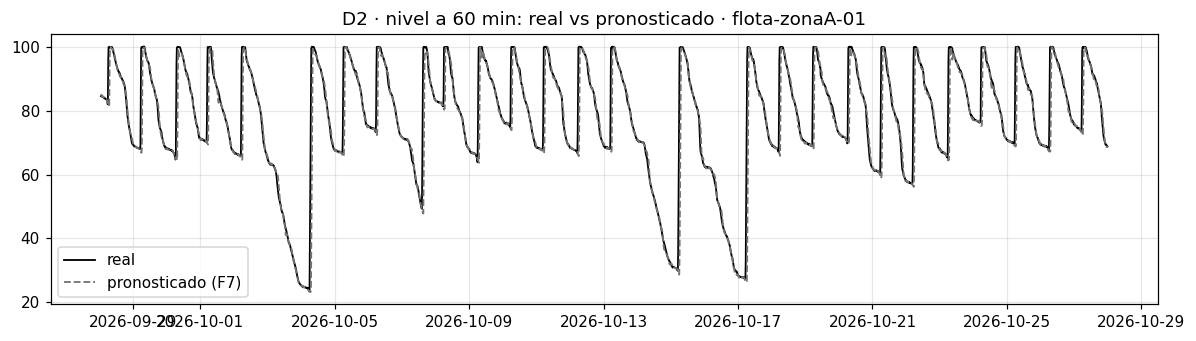

In [17]:
v = ver_flota if len(ver_flota) else ver_real
if len(v) and "nivel_real_pct" in v:
    v = v.dropna(subset=["nivel_real_pct", "nivel_pred_pct"])
    s = v["sensorId"].value_counts().index[0]
    g = v[v["sensorId"] == s].sort_values("_time")
    fig, ax = plt.subplots(figsize=(11, 3.2))
    if 1.0 != 1.0:   # D4: error de la hora de llegada en horas
        ax.bar(g["_time"], (g["nivel_real_pct"] - g["nivel_pred_pct"]) * 1.0, width=0.05, color="0.3")
        ax.axhline(0, color="k", lw=0.8); ax.set_ylabel("real − pronosticada (h)")
    else:
        ax.plot(g["_time"], g["nivel_real_pct"], "k-", lw=1.2, label="real")
        ax.plot(g["_time"], g["nivel_pred_pct"], "--", color="0.45", lw=1.2, label="pronosticado (F7)"); ax.legend()
    ax.set_title(f"D2 · nivel a 60 min: real vs pronosticado · {s}"); plt.tight_layout(); plt.show()

## 7. Limitaciones (copiadas de `docs/modelo-d2.md`)

In [18]:
display(Markdown(su.secciones("modelo-d2.md", ['Limitaciones'])))

## 8. Limitaciones

- **ESP32:**
  - Geometría provisional, así que los % y litros son aproximados.
  - Sesiones cortas e intermitentes: hasta el 29-oct, ningún tramo superaba las 2.4 h.
  - Sin periodo de prueba.
- **DHT11 (±2 °C):** la compensación térmica de la distancia tiene una incertidumbre de ~±0.36 % de la distancia.
  En pronósticos de pocas décimas de punto, eso es del mismo orden que el error.
- **ThingSpeak es de otro país:** son tanques de terceros, con otros hábitos de consumo, tamaños y sensores. Sirven
  para probar el **método** con datos reales, no para afirmar cuánto acertará en Juliaca.
- **Muestreo de ThingSpeak 1233810 (cada ~10 min):** en la rejilla de 5 min no tiene observación a 15 min exactos.
  Entra en la evaluación a 60 min y en autonomía, pero no a 15 min.
- **Pocos episodios no censurados:** 3 en la flota y 2 en ThingSpeak. Los intervalos son anchos y un solo
  episodio pesa mucho.
- **Snapshot:** volver a descargar las fuentes mueve la semana de prueba de ThingSpeak. Las cifras valen para el
  snapshot guardado en la evidencia.

### Limitaciones propias de d2.2

- **Pocos episodios no censurados:** igual que en d2.1. El C-index ayuda porque usa todos los casos.
- **ThingSpeak 480876 queda fuera:** no tiene historia de entrenamiento.
- **El perfil del ESP32 no sirve todavía:** se aprendió con la geometría provisional y con muy pocas horas de
  consumo real. Su consumo medio (1.85 %/h) sale de los saltos del sensor, no de gasto real. Hay que reaprenderlo
  cuando la geometría esté medida y haya sesiones con consumo.
- **El perfil no se actualiza solo en F7:** es una tabla fija. Para que siga los cambios de hábito hay que
  reentrenarlo periódicamente (por ejemplo, cada semana) con `batch/modelo_d2_perfil.py`.
